In [1]:
import torch
from torch import nn


def conv_block(in_channels, out_channels, dropout=0):
    """Two consecutive 3x3 convolutions, followed by ReLU."""
    layers = [
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.ReLU(),
    ]

    # Apply dropout only where requested by the architecture.
    if dropout:
        layers.append(nn.Dropout(dropout))

    return nn.Sequential(*layers)

In [2]:
# Architecture adapted from GeeksforGeeks:
# https://www.geeksforgeeks.org/deep-learning/image-segmentation-using-u-net/
# Adaptations: PyTorch, single-channel MRI input, 16 starting filters, and raw output logits for CrossEntropyLoss.

class UNet(nn.Module):
    """Four-level 2D U-Net for multiclass MRI segmentation."""

    def __init__(self, classes=6, base=16):
        super().__init__()

        # Feature channels at each depth: [16, 32, 64, 128, 256].
        widths = [base * 2**i for i in range(5)]

        # ModuleList registers the blocks so PyTorch can train their weights.
        self.encoders = nn.ModuleList()
        in_channels = 1  # Grayscale MRI has one intensity channel.

        for i, width in enumerate(widths):
            self.encoders.append(
                conv_block(
                    in_channels,
                    width,
                    # Apply dropout in the two deepest blocks.
                    dropout=0.3 if i >= 3 else 0,
                )
            )

            # The next block receives this block's output channels.
            in_channels = width

        # Halve height and width by taking the maximum in each 2×2 region.
        self.pool = nn.MaxPool2d(2)

        self.upsamples = nn.ModuleList()
        self.decoders = nn.ModuleList()

        # Build the decoder from deepest to shallowest level.
        # i takes the values 4, 3, 2, 1.
        for i in range(4, 0, -1):
            self.upsamples.append(
                nn.ConvTranspose2d(
                    widths[i],
                    widths[i - 1],
                    kernel_size=3,
                    stride=2,         # Double height and width.
                    padding=1,
                    output_padding=1, # Resolve output size to exactly double.
                )
            )

            # Upsampled features and matching encoder features are joined.
            # Each has widths[i - 1] channels, giving twice that many inputs.
            self.decoders.append(
                conv_block(2 * widths[i - 1], widths[i - 1])
            )

        # Convert the final 16 features into six class scores per pixel.
        # A 1×1 convolution combines channels without changing image size.
        self.output = nn.Conv2d(base, classes, kernel_size=1)

        # Initialise feature-extraction Conv2d weights for ReLU activations.
        # These are starting weights, not pretrained weights.
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d) and layer is not self.output:
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        # Four halvings require dimensions divisible by 16
        # so the encoder and decoder feature maps match.
        if x.shape[-2] % 16 or x.shape[-1] % 16:
            raise ValueError("Input height and width must be divisible by 16")

        skips = []

        # Process the first four encoder blocks.
        # Save their outputs before pooling, preserving finer spatial detail.
        for encoder in self.encoders[:-1]:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)

        # Process the deepest block without further downsampling.
        x = self.encoders[-1](x)

        # Match each decoder stage with the corresponding encoder output,
        # starting with the deepest saved features.
        for upsample, decoder, skip in zip(
            self.upsamples, self.decoders, reversed(skips)
        ):
            x = upsample(x)

            # Join feature maps along dimension 1: the channel dimension.
            # This concatenates features; it does not add their values.
            x = decoder(torch.cat([x, skip], dim=1))

        # Returns raw scores (logits)
        return self.output(x)

In [7]:
# Sanity test: check input shape, output shape, and parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

model = UNet(classes=6, base=16).to(device)

# Simulate a batch with the same shape produced by dataset loader (dataset.ipynb).
dummy_images = torch.randn(16, 1, 256, 128, device=device)
model.eval()
with torch.no_grad():
    outputs = model(dummy_images)

# Do output shape text
assert outputs.shape == (16, 6, 256, 128)
assert torch.isfinite(outputs).all().item()

# Print results
print("Device:", device)
print("Input shape:", tuple(dummy_images.shape))
print("Output shape:", tuple(outputs.shape))
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# Delete the temporary test tensors.
del dummy_images, outputs

Device: cuda
Input shape: (16, 1, 256, 128)
Output shape: (16, 6, 256, 128)
Parameters: 2,158,502


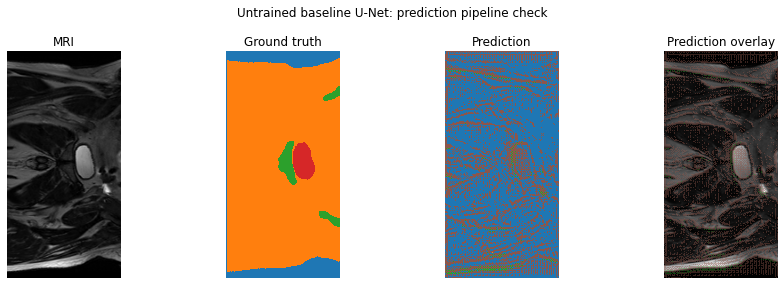

In [8]:
# Sanity test: use an unweighted UNet and show predictions
from pathlib import Path
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Load one training MRI and its matching reference mask.
data_dir = Path("data/keras_slices_data")
image_path = sorted((data_dir / "keras_slices_train").glob("*.nii.gz"))[0]
mask_path = (data_dir / "keras_slices_seg_train" / image_path.name.replace("case_", "seg_", 1))
image = np.squeeze(nib.load(image_path).get_fdata(dtype=np.float32))
mask = np.squeeze(nib.load(mask_path).get_fdata())

# Apply the same normalisation used by the dataset loader.
normalised = (image - image.mean()) / (image.std() + 1e-8)

# Prepare model input
inputs = torch.from_numpy(normalised).unsqueeze(0).unsqueeze(0).to(device)

# Generate prdiction
model.eval()
with torch.no_grad():
    # Select the highest-scoring class at each pixel.
    prediction = model(inputs).argmax(dim=1)[0].cpu().numpy()
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
colours = dict(
    cmap="tab10", vmin=0, vmax=9, interpolation="nearest"
)

# Base MRI
axes[0].imshow(image, cmap="gray")
# Ground truth
axes[1].imshow(mask, **colours)
# Prediction
axes[2].imshow(prediction, **colours)

# Hide predicted label 0 to leave the underlying MRI visible.
# Prediction overlay
axes[3].imshow(image, cmap="gray")
axes[3].imshow(
    np.ma.masked_where(prediction == 0, prediction),
    alpha=0.4,
    **colours,
)

# Display the four plots
for ax, title in zip(
    axes, ["MRI", "Ground truth", "Prediction", "Prediction overlay"]
):
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Untrained baseline U-Net: prediction pipeline check")
plt.tight_layout()
plt.show()